# PathSnap: comparison of the five candidate-scoring models

Every number in this notebook is read from the files written by the five training runs (`../modelN/results.json`,
`fold_results.csv`, `per_trip_top1.csv`, `student_predictions.parquet`, `config.json`). Nothing is typed in by hand.
All five models were evaluated with the same code (`common/experiment.py`, `common/metrics.py`): the same 5 trip-grouped
CV folds on the 80 training trips, the same 22 features, the same fit rows (`fit_include == True`), and student-test
(10 trips) used for evaluation only.

**Partitions.** "CV" = out-of-fold predictions on the **train** partition (80 trips). "Student" = the **student_test**
partition (10 trips). The evaluator partition is never used.

## Metric definitions (same as `common/metrics.py`)

* **Top-1 (all points)**: per GPS point, the highest-scoring candidate is compared with the aligned label arc. Points
  whose label arc is not among the candidates count as misses. **Top-1 (label in candidates)** uses only the points
  whose label arc is a candidate.
* **Macro F1** (our own definition; the guidelines do not define it): candidate level, top-scoring candidate of each
  point = 1, all others = 0; mean of F1(class 1) and F1(class 0).
* **Log loss (raw)**: binary cross-entropy of raw candidate probabilities over all rows. **Log loss (normalised)**:
  probabilities normalised within each point (HMM emission view), mean of -log p(true arc) over points whose label is
  a candidate.
* **Candidate miss rate**: share of points whose label arc is not a candidate (identical for all models: ceiling on Top-1).
* **Route continuity**: share of consecutive top-1 arcs (GPS order, repeats collapsed) that connect in the trip's network.
* **ECE / Brier**: calibration of the raw probabilities.
* **Inference time**: model prediction only, per 1,000 GPS points, student partition, features already built.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "comparison" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from common import plotting

FIG = ROOT / "comparison" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)

MODELS = {   # folder -> short label used in tables and plots
    "model1": "LogReg", "model2": "KNN", "model3": "RandomForest", "model4": "LightGBM", "model5": "MLP",
}
res = {m: json.loads((ROOT / m / "results.json").read_text()) for m in MODELS}
cfg = {m: json.loads((ROOT / m / "config.json").read_text()) for m in MODELS}
folds = pd.concat([pd.read_csv(ROOT / m / "fold_results.csv").assign(model=MODELS[m]) for m in MODELS], ignore_index=True)
print({MODELS[m]: r["seeds"] for m, r in res.items()})

{'LogReg': [42], 'KNN': [42], 'RandomForest': [42], 'LightGBM': [42], 'MLP': [42, 43, 44]}


## Key configuration of each model (from each `config.json`)

In [2]:
def key_config(m):
    h = cfg[m]["hyperparameters"]
    if m == "model1": return f"L2, C={h['C']}, lbfgs, class-weighted + sample weights, scaled table"
    if m == "model2": return f"k={h['n_neighbors']}, distance-weighted, euclidean, {h['subsample_rows']:,}-row subsample, no sample weights, scaled table"
    if m == "model3": return f"{h['n_estimators']} trees, max_depth={h['max_depth']}, min_leaf={h['min_samples_leaf']}, max_samples={h['max_samples']}, sqrt features, sample weights, raw table"
    if m == "model4": return f"lr={h['learning_rate']}, leaves={h['num_leaves']}, min_child={h['min_child_samples']}, early stop {h['early_stopping_rounds']} on 20% trips then refit, sample weights, raw table"
    if m == "model5": return f"22-{h['hidden_units']}-1 ReLU, dropout {h['dropout']}, Adam lr={h['learning_rate']}, batch {h['batch_size']}, early stop (patience {h['patience']}), 3 seeds, sample weights, scaled table"

def size_mb(m):
    files = [f for f in res[m]["saved_files"] if f not in ("scaler.joblib",) and not f.endswith(".json")]
    return round(sum((ROOT / m / f).stat().st_size for f in files) / 1e6, 2)

for m in MODELS: print(f"{MODELS[m]:13s} {key_config(m)}")

LogReg        L2, C=1.0, lbfgs, class-weighted + sample weights, scaled table
KNN           k=50, distance-weighted, euclidean, 150,000-row subsample, no sample weights, scaled table
RandomForest  100 trees, max_depth=12, min_leaf=100, max_samples=0.3, sqrt features, sample weights, raw table
LightGBM      lr=0.05, leaves=63, min_child=100, early stop 100 on 20% trips then refit, sample weights, raw table
MLP           22-64-1 ReLU, dropout 0.1, Adam lr=0.001, batch 4096, early stop (patience 5), 3 seeds, sample weights, scaled table


## Consolidated comparison table → `model_comparison.csv`

In [3]:
rows = []
for m, r in res.items():
    cv, st, tr = r["cv"]["all"], r["student"]["all"], r["train"]["all"]
    note = []
    if m == "model2":
        note.append("training time = storing a 150k-row subsample (lazy learner); cost moves to inference")
        note.append("sample weights N/A in sklearn KNN")
    if m == "model1":
        note.append("raw probabilities shifted by class weights (poor raw calibration by design)")
    if m == "model5":
        note.append("mean of 3 seeds; seed spread in model5/results.json seed_std")
    rows.append({
        "model": MODELS[m], "family": r["family"], "key_configuration": key_config(m),
        "cv_top1_all_mean": cv["top1_all"]["mean"], "cv_top1_all_std": cv["top1_all"]["std"],
        "cv_top1_in_cands_mean": cv["top1_in_cands"]["mean"], "cv_top1_in_cands_std": cv["top1_in_cands"]["std"],
        "cv_macro_f1_mean": cv["macro_f1"]["mean"], "cv_macro_f1_std": cv["macro_f1"]["std"],
        "cv_logloss_raw_mean": cv["logloss_raw"]["mean"], "cv_logloss_norm_mean": cv["logloss_norm"]["mean"],
        "cv_clean_top1_all_mean": r["cv"]["clean"]["top1_all"]["mean"],
        "train_top1_all": tr["top1_all"],
        "route_continuity_cv": r["route_continuity"]["cv_oof"]["pooled"],
        "route_continuity_student": r["route_continuity"]["student"]["pooled"],
        "student_top1_all": st["top1_all"], "student_top1_in_cands": st["top1_in_cands"],
        "student_macro_f1": st["macro_f1"],
        "student_logloss_raw": st["logloss_raw"], "student_logloss_norm": st["logloss_norm"],
        "student_clean_top1_all": r["student"]["clean"]["top1_all"],
        "student_ece": st["ece"], "student_brier": st["brier"],
        "candidate_miss_rate_train": r["candidate_miss_rate"]["train"], "candidate_miss_rate_student": r["candidate_miss_rate"]["student"],
        "final_fit_seconds": r["timing"]["final_fit_seconds"],
        "inference_ms_per_1000_points": r["timing"]["inference_ms_per_1000_points"],
        "model_file_mb": size_mb(m),
        "notes": "; ".join(note) if note else "",
    })
comp = pd.DataFrame(rows)
comp.to_csv(ROOT / "comparison" / "model_comparison.csv", index=False)
show = ["model", "cv_top1_all_mean", "cv_top1_all_std", "cv_top1_in_cands_mean", "cv_macro_f1_mean", "cv_logloss_norm_mean",
        "route_continuity_cv", "student_top1_all", "student_macro_f1", "student_logloss_raw", "student_logloss_norm",
        "student_ece", "final_fit_seconds", "inference_ms_per_1000_points", "model_file_mb"]
comp[show].round(4)

,model,cv_top1_all_mean,cv_top1_all_std,cv_top1_in_cands_mean,cv_macro_f1_mean,cv_logloss_norm_mean,route_continuity_cv,student_top1_all,student_macro_f1,student_logloss_raw,student_logloss_norm,student_ece,final_fit_seconds,inference_ms_per_1000_points,model_file_mb
0,LogReg,0.7584,0.1269,0.8347,0.8839,0.7790,0.7119,0.8326,0.9081,0.1835,0.7357,0.0849,2.79,0.1980,0.00
1,KNN,0.7582,0.1258,0.8346,0.8838,1.1738,0.7057,0.8428,0.9138,0.1141,0.7614,0.0039,0.11,1072.3280,7.50
2,RandomForest,0.7652,0.1264,0.8426,0.8879,0.5024,0.7126,0.8447,0.9148,0.0739,0.4462,0.0117,27.71,20.0630,4.43
3,LightGBM,0.7733,0.1291,0.8514,0.8926,0.4461,0.7285,0.8636,0.9252,0.0679,0.4018,0.0057,16.29,9.4640,0.55
4,MLP,0.7734,0.1286,0.8515,0.8927,0.4784,0.7305,0.8593,0.9229,0.0701,0.4076,0.0015,71.71,3.5217,0.03


## Applying the selection rule (primary CV Top-1 on all points, tie-breaker normalised log loss)

What counts as a tie: a CV Top-1 difference smaller than the **seed-to-seed spread** we measured (the std of the
MLP's CV Top-1 over its 3 seeds). A difference that small can come from re-running the same model with another seed,
so it cannot rank two models. Tied models are then ranked by CV log loss (normalised per point, the HMM view).

In [4]:
TIE_TOL = res["model5"]["seed_std"]["cv"]["all"]["top1_all"]["mean"]   # measured, not chosen by hand
top = comp["cv_top1_all_mean"].max()
tied = comp[comp["cv_top1_all_mean"] >= top - TIE_TOL]
best = tied.sort_values("cv_logloss_norm_mean").iloc[0]["model"]
print(f"tie tolerance (MLP seed std of CV Top-1): {TIE_TOL:.5f}")
print("models tied on CV Top-1:", tied["model"].tolist())
display(tied[["model", "cv_top1_all_mean", "cv_logloss_norm_mean", "student_top1_all", "student_logloss_norm"]].round(5))
print("MLP per seed (CV Top-1, CV normalised log loss):",
      {s: (round(v["cv"]["all"]["top1_all"]["mean"], 5), round(v["cv"]["all"]["logloss_norm"]["mean"], 4)) for s, v in res["model5"]["per_seed"].items()})
print(f"Selected by the rule: {best}")

tie tolerance (MLP seed std of CV Top-1): 0.00061
models tied on CV Top-1: ['LightGBM', 'MLP']


,model,cv_top1_all_mean,cv_logloss_norm_mean,student_top1_all,student_logloss_norm
3,LightGBM,0.77329,0.44606,0.86357,0.40177
4,MLP,0.77343,0.47838,0.85934,0.40757


MLP per seed (CV Top-1, CV normalised log loss): {'42': (0.77318, 0.4767), '43': (0.77284, 0.479), '44': (0.77426, 0.4794)}
Selected by the rule: LightGBM


## Fold-by-fold Top-1 (all points): stability and paired differences

The fold standard deviation is large for every model because folds differ in how many far / uncovered points they hold
(the same trips are in the same fold for every model). Because all models share the folds, the **paired per-fold
difference** to the best model is the fairer stability check.

In [5]:
ft = folds[(folds.subset == "all")].groupby(["model", "fold"])["top1_all"].mean().unstack("fold")
ft = ft.loc[[MODELS[m] for m in MODELS]]
diff = ft.sub(ft.loc[best], axis=1)
diff["mean_diff"] = diff.mean(axis=1); diff["folds_worse"] = (diff.drop(columns="mean_diff") < 0).sum(axis=1)
print("Top-1 (all) per fold:"); display(ft.round(4))
print(f"Paired difference to {best} (negative = worse than {best}):"); display(diff.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
for mdl, row in ft.iterrows(): ax.plot(row.index, row.values, marker="o", label=mdl)
ax.set_xlabel("CV fold (train partition)"); ax.set_ylabel("Top-1 (all points)"); ax.set_xticks(ft.columns)
ax.set_title("Top-1 per CV fold, all five models"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG / "cv_top1_per_fold.png", dpi=130); plt.show()

Top-1 (all) per fold:


fold,0,1,2,3,4
model,,,,,
LogReg,0.8210,0.8746,0.5439,0.7623,0.7903
KNN,0.8185,0.8739,0.5454,0.7637,0.7893
RandomForest,0.8226,0.8895,0.5546,0.7650,0.7941
LightGBM,0.8185,0.9066,0.5597,0.7740,0.8077
MLP,0.8350,0.8978,0.5591,0.7724,0.8027


Paired difference to LightGBM (negative = worse than LightGBM):


fold,0,1,2,3,4,mean_diff,folds_worse
model,,,,,,,
LogReg,0.0025,-0.0320,-0.0158,-0.0117,-0.0174,-0.0149,4
KNN,0.0001,-0.0328,-0.0143,-0.0103,-0.0184,-0.0151,4
RandomForest,0.0041,-0.0171,-0.0051,-0.0090,-0.0136,-0.0081,4
LightGBM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0
MLP,0.0165,-0.0088,-0.0006,-0.0016,-0.0049,0.0001,4


C:\Users\shiva\AppData\Local\Temp\ipykernel_43376\1297895090.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "cv_top1_per_fold.png", dpi=130); plt.show()


## Comparison plots (all from the results files)

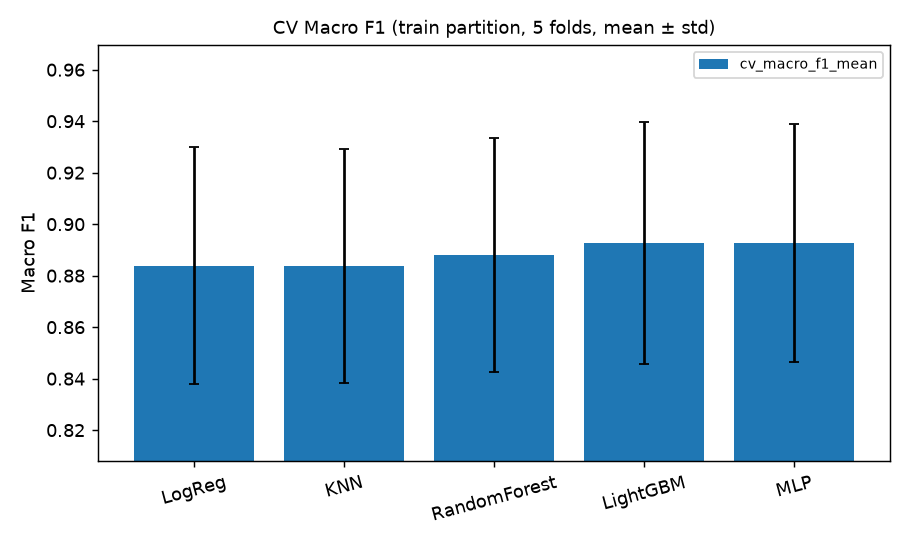

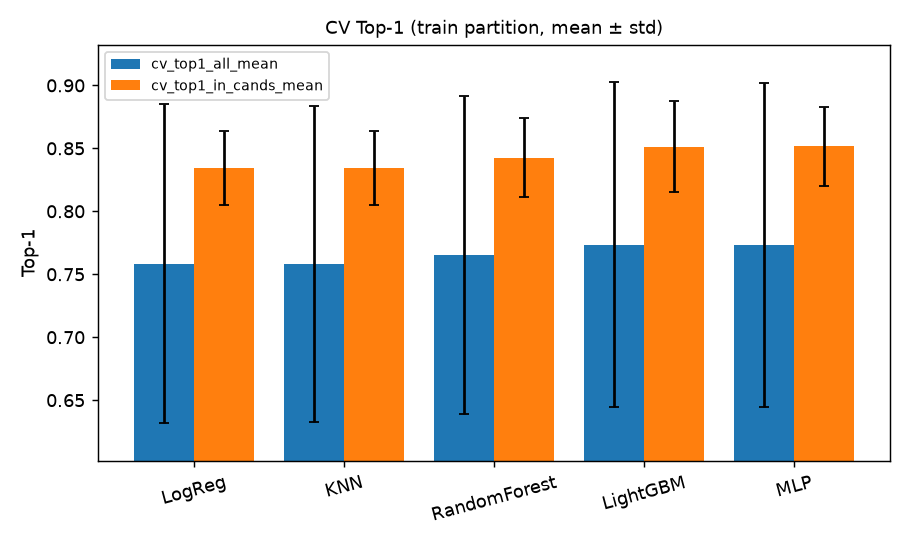

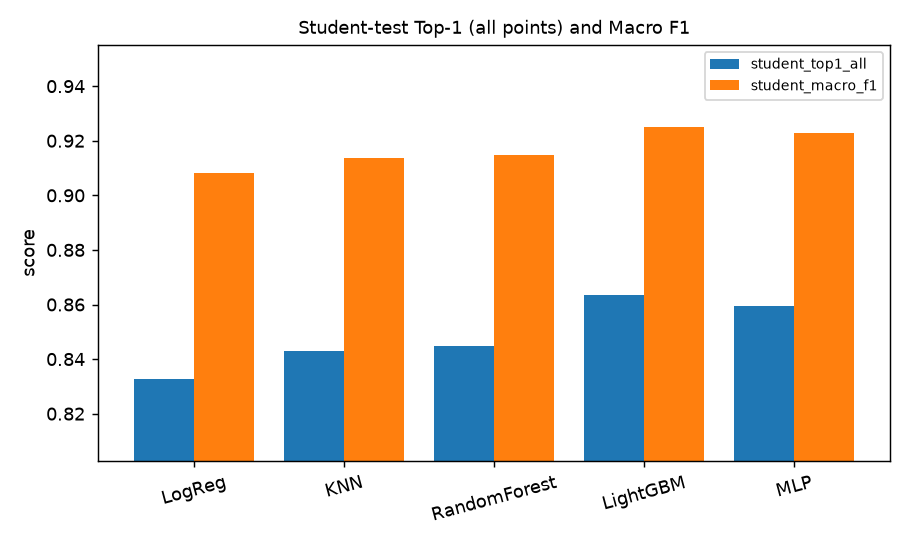

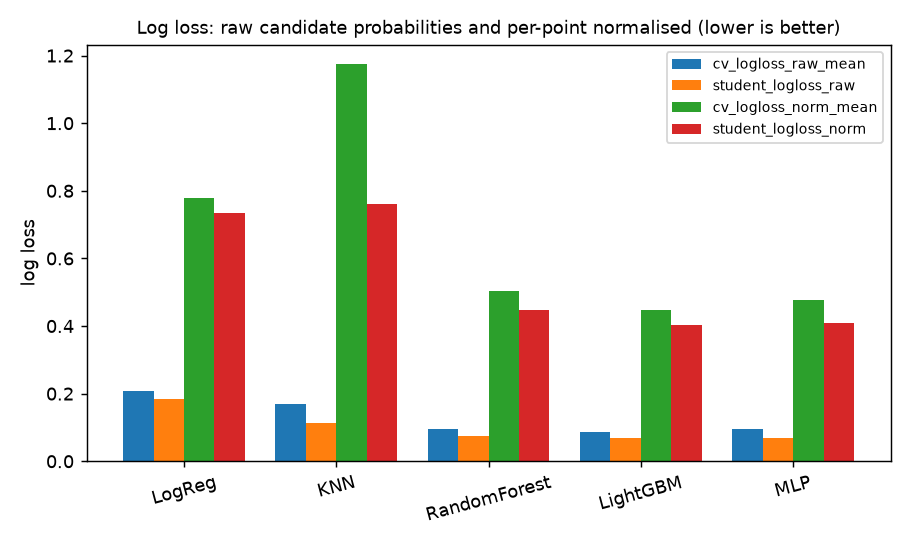

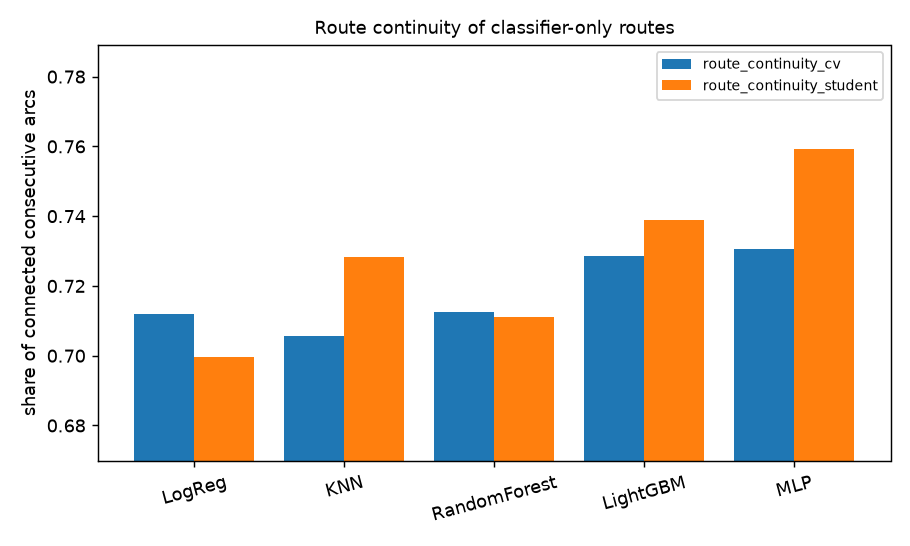

In [6]:
plotting.plot_model_bars(comp, ["cv_macro_f1_mean"], "CV Macro F1 (train partition, 5 folds, mean ± std)", "Macro F1",
                         FIG / "cv_macro_f1.png", err={"cv_macro_f1_mean": "cv_macro_f1_std"})
plotting.plot_model_bars(comp, ["cv_top1_all_mean", "cv_top1_in_cands_mean"], "CV Top-1 (train partition, mean ± std)", "Top-1",
                         FIG / "cv_top1.png", err={"cv_top1_all_mean": "cv_top1_all_std", "cv_top1_in_cands_mean": "cv_top1_in_cands_std"})
plotting.plot_model_bars(comp, ["student_top1_all", "student_macro_f1"], "Student-test Top-1 (all points) and Macro F1", "score",
                         FIG / "student_top1_macro_f1.png")
plotting.plot_model_bars(comp, ["cv_logloss_raw_mean", "student_logloss_raw", "cv_logloss_norm_mean", "student_logloss_norm"],
                         "Log loss: raw candidate probabilities and per-point normalised (lower is better)", "log loss",
                         FIG / "log_loss.png")
plotting.plot_model_bars(comp, ["route_continuity_cv", "route_continuity_student"], "Route continuity of classifier-only routes",
                         "share of connected consecutive arcs", FIG / "route_continuity.png")
for f in ["cv_macro_f1", "cv_top1", "student_top1_macro_f1", "log_loss", "route_continuity"]:
    display(__import__("IPython").display.Image(str(FIG / f"{f}.png")))

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(comp["model"], comp["inference_ms_per_1000_points"])
ax.set_yscale("log"); ax.set_ylabel("ms per 1,000 GPS points (log scale)")
ax.set_title("Inference time (student partition, model prediction only)"); fig.tight_layout()
fig.savefig(FIG / "inference_time.png", dpi=130); plt.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_43376\3956436619.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "inference_time.png", dpi=130); plt.show()


## Train vs CV vs student (over- / under-fitting evidence)

In [8]:
gap = comp[["model", "train_top1_all", "cv_top1_all_mean", "student_top1_all"]].copy()
gap["train_minus_cv"] = gap.train_top1_all - gap.cv_top1_all_mean
gap["cv_minus_student"] = gap.cv_top1_all_mean - gap.student_top1_all
display(gap.round(4))
x = np.arange(len(gap)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 4))
for i, c in enumerate(["train_top1_all", "cv_top1_all_mean", "student_top1_all"]):
    ax.bar(x + (i - 1) * w, gap[c], w, label=c)
ax.set_xticks(x, gap.model); ax.set_ylim(0.6, 1.0); ax.set_ylabel("Top-1 (all points)")
ax.set_title("Train (refit, in-sample) vs CV (out-of-fold) vs student-test"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG / "train_cv_student_gap.png", dpi=130); plt.show()

,model,train_top1_all,cv_top1_all_mean,student_top1_all,train_minus_cv,cv_minus_student
0,LogReg,0.7528,0.7584,0.8326,-0.0056,-0.0741
1,KNN,0.7947,0.7582,0.8428,0.0366,-0.0846
2,RandomForest,0.7759,0.7652,0.8447,0.0107,-0.0796
3,LightGBM,0.7971,0.7733,0.8636,0.0239,-0.0903
4,MLP,0.7809,0.7734,0.8593,0.0075,-0.0859


C:\Users\shiva\AppData\Local\Temp\ipykernel_43376\3015694764.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "train_cv_student_gap.png", dpi=130); plt.show()


## Confusion matrices (student-test, candidate level at the top-1 decision; optional diagnostic)

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, m in zip(axes, MODELS):
    cm = np.asarray(res[m]["confusion_matrix"]["student_all"])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{int(round(v)):,}", ha="center", va="center", fontsize=8)
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["true 0", "true 1"]); ax.set_title(MODELS[m], fontsize=9)
fig.suptitle("Student-test confusion matrices (rows = truth, columns = top-1 decision)", fontsize=10); fig.tight_layout()
fig.savefig(FIG / "confusion_matrices_student.png", dpi=130); plt.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_43376\1244245149.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(FIG / "confusion_matrices_student.png", dpi=130); plt.show()


## Calibration (raw candidate probabilities)

In [10]:
display(comp[["model", "student_ece", "student_brier", "student_logloss_raw", "student_logloss_norm"]].round(4))
cal = {MODELS[m]: res[m]["cv_oof_pooled"]["all"]["ece"] for m in MODELS}
print("CV out-of-fold ECE:", {k: round(v, 4) for k, v in cal.items()})

,model,student_ece,student_brier,student_logloss_raw,student_logloss_norm
0,LogReg,0.0849,0.0583,0.1835,0.7357
1,KNN,0.0039,0.0235,0.1141,0.7614
2,RandomForest,0.0117,0.0205,0.0739,0.4462
3,LightGBM,0.0057,0.0190,0.0679,0.4018
4,MLP,0.0015,0.0201,0.0701,0.4076


CV out-of-fold ECE: {'LogReg': 0.093, 'KNN': 0.0072, 'RandomForest': 0.0163, 'LightGBM': 0.0076, 'MLP': 0.0083}


## Per-trip Top-1 of the best model (weak trips)

In [11]:
best_folder = [m for m, lab in MODELS.items() if lab == best][0]
pt = pd.read_csv(ROOT / best_folder / "per_trip_top1.csv", dtype={"trip_id": str})
if "seed" in pt: pt = pt.groupby(["partition", "trip_id"], as_index=False).mean(numeric_only=True)
pt["weak_trip"] = pt["top1_all"] < 0.80
FAR_HEAVY = ["00000054", "00000033", "00000002"]   # far-heavy trips named in the preprocessing report
cols = ["partition", "trip_id", "n_points", "top1_all", "top1_in_cands", "miss_rate", "far_share", "route_continuity"]
print(f"Selected model: {best}")
print("Weak trips (Top-1 all < 0.80):"); display(pt[pt.weak_trip][cols].sort_values(["partition", "top1_all"]).round(3))
print("Far-heavy trips from the preprocessing report:"); display(pt[pt.trip_id.isin(FAR_HEAVY)][cols].round(3))
print("Student trips:"); display(pt[pt.partition == "student"][cols].sort_values("top1_all").round(3))

Selected model: LightGBM
Weak trips (Top-1 all < 0.80):


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
8,student,00000077,3911.0,0.763,0.763,0.000,0.003,0.744
54,train_cv_oof,00000054,19313.0,0.086,0.648,0.867,0.894,0.372
36,train_cv_oof,00000033,5844.0,0.195,0.468,0.582,0.712,0.777
27,train_cv_oof,00000022,474.0,0.580,0.580,0.000,0.002,0.474
59,train_cv_oof,00000061,1430.0,0.592,0.597,0.008,0.037,0.583
11,train_cv_oof,00000002,7243.0,0.595,0.658,0.096,0.140,0.685
17,train_cv_oof,00000010,2711.0,0.640,0.640,0.000,0.005,0.381
16,train_cv_oof,00000008,3093.0,0.643,0.648,0.007,0.039,0.603
22,train_cv_oof,00000016,1305.0,0.645,0.645,0.000,0.041,0.662
68,train_cv_oof,00000072,969.0,0.692,0.692,0.000,0.001,0.485


Far-heavy trips from the preprocessing report:


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
11,train_cv_oof,00000002,7243.0,0.595,0.658,0.096,0.140,0.685
36,train_cv_oof,00000033,5844.0,0.195,0.468,0.582,0.712,0.777
54,train_cv_oof,00000054,19313.0,0.086,0.648,0.867,0.894,0.372


Student trips:


,partition,trip_id,n_points,top1_all,top1_in_cands,miss_rate,far_share,route_continuity
8,student,00000077,3911.0,0.763,0.763,0.000,0.003,0.744
6,student,00000065,768.0,0.820,0.820,0.000,0.000,0.786
2,student,00000009,1049.0,0.827,0.829,0.002,0.018,0.728
7,student,00000076,1486.0,0.847,0.847,0.000,0.001,0.650
9,student,00000091,874.0,0.857,0.857,0.000,0.000,0.653
5,student,00000056,3958.0,0.864,0.870,0.007,0.010,0.734
1,student,00000007,1354.0,0.913,0.913,0.000,0.020,0.981
4,student,00000052,262.0,0.924,0.924,0.000,0.000,0.831
3,student,00000040,2995.0,0.932,0.932,0.000,0.016,0.760
0,student,00000000,2503.0,0.946,0.946,0.000,0.001,0.700


## Model selection: summary table

In [12]:
rank = comp.sort_values(["cv_top1_all_mean", "cv_logloss_norm_mean"], ascending=[False, True])
display(rank[["model", "cv_top1_all_mean", "cv_top1_all_std", "cv_top1_in_cands_mean", "cv_logloss_norm_mean",
              "student_top1_all", "student_logloss_norm", "student_ece", "inference_ms_per_1000_points", "model_file_mb"]].round(4))

,model,cv_top1_all_mean,cv_top1_all_std,cv_top1_in_cands_mean,cv_logloss_norm_mean,student_top1_all,student_logloss_norm,student_ece,inference_ms_per_1000_points,model_file_mb
4,MLP,0.7734,0.1286,0.8515,0.4784,0.8593,0.4076,0.0015,3.5217,0.03
3,LightGBM,0.7733,0.1291,0.8514,0.4461,0.8636,0.4018,0.0057,9.4640,0.55
2,RandomForest,0.7652,0.1264,0.8426,0.5024,0.8447,0.4462,0.0117,20.0630,4.43
0,LogReg,0.7584,0.1269,0.8347,0.7790,0.8326,0.7357,0.0849,0.1980,0.00
1,KNN,0.7582,0.1258,0.8346,1.1738,0.8428,0.7614,0.0039,1072.3280,7.50


## Justification of the chosen model: LightGBM

*(Numbers below are the outputs printed above; they come from the five `results.json` files.)*

1. **Primary metric is a tie between LightGBM and the MLP.** CV Top-1 on all points: MLP 0.7734 (mean of 3 seeds) vs
   LightGBM 0.7733, a 0.0001 difference. Re-running the MLP with another seed moves its CV Top-1 by 0.0006 (std over
   seeds), six times more, and two of the three MLP seeds (0.7732, 0.7728) are below LightGBM. Paired per fold,
   LightGBM is ahead on folds 1-4 and behind on fold 0. Random Forest (0.7652), Logistic Regression (0.7584) and KNN
   (0.7582) are behind the MLP on all 5 folds, so they are clearly second tier.
2. **Tie-breaker (normalised log loss, what the HMM uses): LightGBM wins clearly.** CV 0.446 vs MLP 0.478, and the
   student partition agrees (0.402 vs 0.408). LightGBM's per-point probabilities put more mass on the true arc, which
   is exactly what the HMM emission needs.
3. **Other criteria.** LightGBM has the best student Top-1 (0.864 vs 0.859) and Macro F1 (0.925), is well calibrated
   (student ECE 0.006), and is deterministic (one seed, no seed spread). Inference (~9.5 ms per 1,000 points) is slower
   than the MLP (~3.5 ms) but far below anything that matters for a 10-trip demo. Its model file is 0.55 MB.
   It also has a well-understood Bayesian search space (learning rate, leaves, min child samples, regularisation).
4. **Not chosen.** The MLP is the runner-up and a reasonable alternative: tied Top-1, the best route continuity
   (student 0.759 vs 0.739), tiny and fast, but worse log loss and seed-dependent. KNN is slow at inference
   (~1,070 ms per 1,000 points) with poor normalised log loss; Logistic Regression is the weakest ranker and is badly
   calibrated by its class weights.

**Over- / under-fitting.** Train (in-sample refit) minus CV Top-1 is small for every model (LightGBM +0.024, MLP
+0.008, RF +0.011, LogReg -0.006), so none memorises the training trips; KNN's +0.037 is the largest, as expected for
a model that stores training rows. Student-test scores are higher than CV for every model because the student trips
have almost no uncovered points (miss rate 0.15% vs 10.4%), not because of leakage: on points whose label is a
candidate, CV and student Top-1 are much closer.